# Attention-Based Bidirectional GRU for Pizza-Review Sentiment Classification

****  
**Topic:** Improving recurrent sentiment classification with bidirectional context and additive attention

This notebook extends the CA1 Pizza Reviews RNN project. It keeps the same three-class sentiment task
(negative, neutral, positive), but tests whether a bidirectional GRU and an attention-pooling layer improve
on a standard GRU. All models use the same preprocessing, stratified splits, vocabulary, optimiser,
early-stopping policy, and class weights so the comparison is fair.

## 1. Research question and hypotheses

**Research question.** Can an attention-based bidirectional GRU improve macro F1 on the small, bilingual
Pizza Reviews dataset compared with a unidirectional GRU?

- **H1:** A bidirectional GRU will improve over a unidirectional GRU because it encodes each token using
  both its preceding and following context.
- **H2:** Attention pooling will improve macro F1 by assigning more weight to sentiment-bearing words,
  rather than compressing the full review into only the final recurrent state.
- **Caveat:** The dataset is small, so a larger model can overfit. Validation and held-out test results,
  rather than training accuracy, determine whether an improvement is credible.

## 2. Related work

A standard RNN can struggle to preserve useful information across long sequences because gradients can
decay. LSTM introduced gated memory to address this limitation (Hochreiter & Schmidhuber, 1997).
GRU is a simpler gated alternative with update and reset gates (Cho et al., 2014). A bidirectional RNN
combines left-to-right and right-to-left sequence representations, allowing a token to be interpreted using
context on both sides (Schuster & Paliwal, 1997). Attention avoids relying on a single fixed-length summary:
it learns a soft weighting over hidden states (Bahdanau, Cho, & Bengio, 2015).

This project does not claim that attention must improve every dataset. Instead, it tests the claim under a
controlled, small-data sentiment-classification setting and reports both gains and limitations.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import random
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer

SEEDS = [7, 19, 42]
MAX_WORDS = 3_000
EMBEDDING_DIM = 64
BATCH_SIZE = 32
EPOCHS = 40
DATA_PATH = Path("pizza_reviews.csv")

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

C:\Users\ephra\anaconda3\envs\gpu_env\lib\site-packages\requests\__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


TensorFlow: 2.10.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Dataset and preprocessing

The original CSV contains restaurant reviews with numeric scores and language labels. The cleaning rules
below remove malformed rows, retain English and Malay (the two substantial language groups), and map scores
into the same CA1 classes: negative (0-3), neutral (4-7), and positive (8-10). The split occurs **before**
tokenisation so the vocabulary is learned from training reviews only, preventing test-set leakage.

In [2]:
raw = pd.read_csv(DATA_PATH)
raw = raw.iloc[:, [0, 1, 3]].copy()
raw.columns = ["review", "score", "language"]
raw["score"] = pd.to_numeric(raw["score"], errors="coerce")
raw["review"] = raw["review"].astype(str).str.strip()
raw["language"] = raw["language"].astype(str).str.strip()

data = raw.dropna(subset=["score"]).copy()
data = data[data["review"].str.lower().ne("review")]
data = data[data["language"].isin(["English", "Malay"])]
data = data[data["review"].str.len().gt(1)].copy()
data = data[data["score"].between(0, 10)].copy()

data["label"] = np.select(
    [data["score"] <= 3, data["score"] <= 7],
    [0, 1],
    default=2,
).astype(int)
label_names = ["Negative", "Neutral", "Positive"]

print(f"Usable reviews: {len(data)}")
print(data["language"].value_counts())
print(data["label"].value_counts().sort_index().rename(index=dict(enumerate(label_names))))
data.head()

Usable reviews: 877
English    488
Malay      389
Name: language, dtype: int64
Negative    259
Neutral     267
Positive    351
Name: label, dtype: int64


,review,score,language,label
0,Disgusting.,1.0,English,0
1,Loved the sambal kick!,10.0,English,2
2,Loved the sambal kick!,0.1,English,0
3,Loved the sambal kick!,5.0,English,1
4,"Satay on pizza? Surprisingly worked. Tasty, un...",7.0,English,1


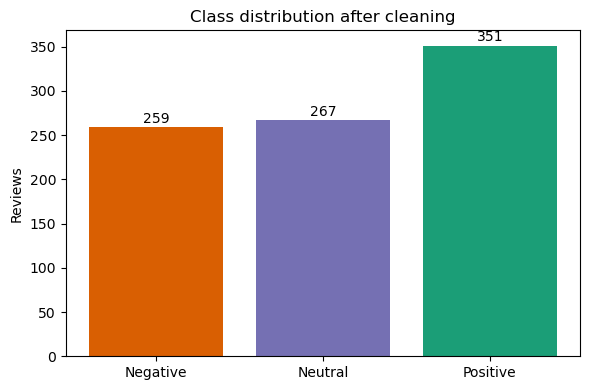

95th-percentile raw review length: 17


In [3]:
plt.figure(figsize=(6, 4))
counts = data["label"].value_counts().sort_index()
plt.bar(label_names, counts, color=["#d95f02", "#7570b3", "#1b9e77"])
plt.ylabel("Reviews")
plt.title("Class distribution after cleaning")
for index, value in enumerate(counts):
    plt.text(index, value + 5, str(value), ha="center")
plt.tight_layout()
plt.show()

review_lengths = data["review"].str.split().str.len()
print("95th-percentile raw review length:", int(review_lengths.quantile(0.95)))

In [4]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

data["text"] = data["review"].map(clean_text)

train_df, temporary_df = train_test_split(
    data, test_size=0.30, random_state=42, stratify=data["label"]
)
val_df, test_df = train_test_split(
    temporary_df, test_size=0.50, random_state=42, stratify=temporary_df["label"]
)

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(train_df["text"])
vocab_size = min(MAX_WORDS, len(tokenizer.word_index) + 1)

train_lengths = train_df["text"].str.split().str.len()
MAX_LEN = max(10, int(np.ceil(train_lengths.quantile(0.95))))

def to_sequences(frame):
    sequence = tokenizer.texts_to_sequences(frame["text"])
    return pad_sequences(sequence, maxlen=MAX_LEN, padding="post", truncating="post")

x_train, x_val, x_test = map(to_sequences, [train_df, val_df, test_df])
y_train = train_df["label"].to_numpy()
y_val = val_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

class_values = np.unique(y_train)
class_weight_values = compute_class_weight(class_weight="balanced", classes=class_values, y=y_train)
class_weights = dict(zip(class_values, class_weight_values))

print(f"Train / validation / test: {len(train_df)} / {len(val_df)} / {len(test_df)}")
print("Vocabulary size:", vocab_size)
print("Maximum sequence length:", MAX_LEN)
print("Class weights:", class_weights)

Train / validation / test: 613 / 132 / 132
Vocabulary size: 721
Maximum sequence length: 17
Class weights: {0: 1.1289134438305708, 1: 1.0926916221033869, 2: 0.8340136054421768}


## 4. Models

Three architectures are compared.

1. **GRU baseline:** a single, forward-only GRU, matching the best basic recurrent family from CA1.
2. **Bidirectional GRU:** processes each review in both directions.
3. **Bidirectional GRU + additive attention:** returns all bidirectional hidden states, then learns a
   normalised weight for every non-padding token. The weighted sum becomes the document representation used
   for three-class classification.

In [5]:
@keras.utils.register_keras_serializable()
class AttentionPooling(layers.Layer):
    """Learn a soft importance weight for each valid recurrent hidden state."""

    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.score_layer = layers.Dense(1)

    def call(self, inputs, mask=None):
        scores = tf.squeeze(self.score_layer(inputs), axis=-1)
        if mask is not None:
            scores += (1.0 - tf.cast(mask, scores.dtype)) * tf.constant(-1e9, scores.dtype)
        weights = tf.nn.softmax(scores, axis=1)
        return tf.reduce_sum(inputs * tf.expand_dims(weights, axis=-1), axis=1)

    def compute_mask(self, inputs, mask=None):
        return None

def set_seed(seed):
    keras.backend.clear_session()
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

def make_model(kind):
    inputs = keras.Input(shape=(MAX_LEN,), dtype="int32")
    x = layers.Embedding(vocab_size, EMBEDDING_DIM, mask_zero=True)(inputs)

    if kind == "gru":
        x = layers.GRU(64, dropout=0.25)(x)
    elif kind == "bigru":
        x = layers.Bidirectional(layers.GRU(64, dropout=0.25))(x)
    elif kind == "bigru_attention":
        x = layers.Bidirectional(layers.GRU(64, dropout=0.25, return_sequences=True))(x)
        x = AttentionPooling(name="attention_pooling")(x)
    else:
        raise ValueError(f"Unknown model kind: {kind}")

    x = layers.Dropout(0.35)(x)
    outputs = layers.Dense(3, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name=kind)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

make_model("bigru_attention").summary()

Model: "bigru_attention"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 input_1 (InputLayer)        [(None, 17)]              0         


 embedding (Embedding)       (None, 17, 64)            46144     


 bidirectional (Bidirectiona  (None, 17, 128)          49920     


... (5 outputs left out)

Total params: 96,580


Trainable params: 96,580


Non-trainable params: 0


_________________________________________________________________


## 5. Experimental protocol

Each architecture is trained with three random seeds. Training uses early stopping on validation loss and
restores the best epoch. Macro F1 is computed after prediction, because it gives equal weight to the three
classes and is more informative than accuracy when neutral reviews are harder to identify.

In [6]:
model_specs = {
    "GRU": "gru",
    "Bidirectional GRU": "bigru",
    "Bidirectional GRU + attention": "bigru_attention",
}

histories = {}
trained_models = {}
records = []

for display_name, kind in model_specs.items():
    for seed in SEEDS:
        set_seed(seed)
        model = make_model(kind)
        callbacks = [
            keras.callbacks.EarlyStopping(
                monitor="val_loss", patience=6, restore_best_weights=True, verbose=0
            )
        ]
        history = model.fit(
            x_train, y_train,
            validation_data=(x_val, y_val),
            class_weight=class_weights,
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            verbose=0,
            callbacks=callbacks,
        )
        val_pred = model.predict(x_val, verbose=0).argmax(axis=1)
        test_pred = model.predict(x_test, verbose=0).argmax(axis=1)
        records.append({
            "model": display_name,
            "seed": seed,
            "best_epoch": int(np.argmin(history.history["val_loss"]) + 1),
            "val_accuracy": float((val_pred == y_val).mean()),
            "val_macro_f1": float(f1_score(y_val, val_pred, average="macro")),
            "test_accuracy": float((test_pred == y_test).mean()),
            "test_macro_f1": float(f1_score(y_test, test_pred, average="macro")),
        })
        histories[(display_name, seed)] = history.history
        trained_models[(display_name, seed)] = model

results = pd.DataFrame(records)
display(results.sort_values(["model", "seed"]))

,model,seed,best_epoch,val_accuracy,val_macro_f1,test_accuracy,test_macro_f1
3,Bidirectional GRU,7,5,0.901515,0.895275,0.878788,0.869133
4,Bidirectional GRU,19,5,0.871212,0.864856,0.871212,0.859187
5,Bidirectional GRU,42,4,0.863636,0.857061,0.863636,0.854660
6,Bidirectional GRU + attention,7,9,0.886364,0.878647,0.893939,0.886097
7,Bidirectional GRU + attention,19,5,0.871212,0.864165,0.863636,0.851646
8,Bidirectional GRU + attention,42,4,0.810606,0.808059,0.803030,0.790842
0,GRU,7,6,0.893939,0.886728,0.848485,0.837019
1,GRU,19,6,0.863636,0.854607,0.840909,0.826581
2,GRU,42,11,0.871212,0.867019,0.871212,0.861570


,val_macro_f1_mean,val_macro_f1_std,test_macro_f1_mean,test_macro_f1_std,test_accuracy_mean
model,,,,,
Bidirectional GRU,0.872,0.020,0.861,0.007,0.871
GRU,0.869,0.016,0.842,0.018,0.854
Bidirectional GRU + attention,0.850,0.037,0.843,0.048,0.854


C:\Users\ephra\AppData\Local\Temp\ipykernel_17452\154613585.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results, x="model", y="test_macro_f1", errorbar="sd", palette="viridis")


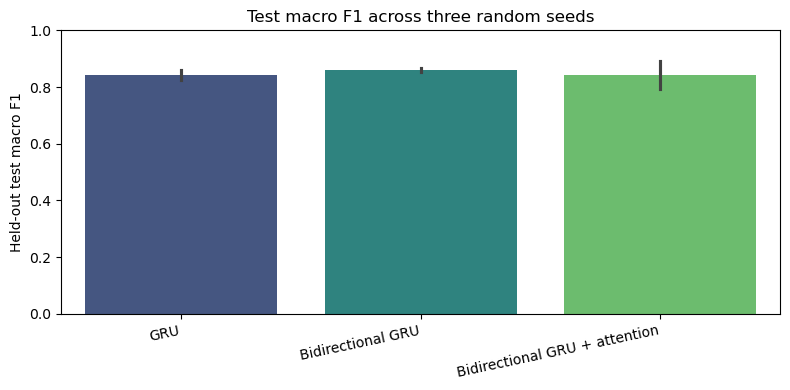

In [7]:
summary = (
    results.groupby("model")
    .agg(
        val_macro_f1_mean=("val_macro_f1", "mean"),
        val_macro_f1_std=("val_macro_f1", "std"),
        test_macro_f1_mean=("test_macro_f1", "mean"),
        test_macro_f1_std=("test_macro_f1", "std"),
        test_accuracy_mean=("test_accuracy", "mean"),
    )
    .sort_values("val_macro_f1_mean", ascending=False)
)
display(summary.style.format("{:.3f}"))

plt.figure(figsize=(8, 4))
sns.barplot(data=results, x="model", y="test_macro_f1", errorbar="sd", palette="viridis")
plt.ylim(0, 1)
plt.xlabel("")
plt.ylabel("Held-out test macro F1")
plt.xticks(rotation=12, ha="right")
plt.title("Test macro F1 across three random seeds")
plt.tight_layout()
plt.show()

Selected model by validation macro F1: Bidirectional GRU (seed 7)
              precision    recall  f1-score   support

    Negative      0.838     0.795     0.816        39
     Neutral      0.868     0.825     0.846        40
    Positive      0.912     0.981     0.945        53

    accuracy                          0.879       132
   macro avg      0.873     0.867     0.869       132
weighted avg      0.877     0.879     0.877       132



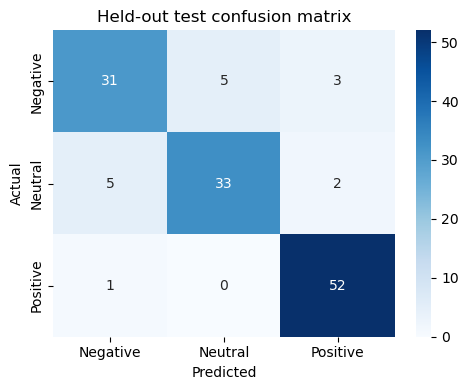

In [8]:
best_row = results.sort_values("val_macro_f1", ascending=False).iloc[0]
best_key = (best_row["model"], int(best_row["seed"]))
best_model = trained_models[best_key]
best_predictions = best_model.predict(x_test, verbose=0).argmax(axis=1)

print("Selected model by validation macro F1:", best_key[0], f"(seed {best_key[1]})")
print(classification_report(y_test, best_predictions, target_names=label_names, digits=3))

matrix = confusion_matrix(y_test, best_predictions)
plt.figure(figsize=(5, 4))
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", xticklabels=label_names, yticklabels=label_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Held-out test confusion matrix")
plt.tight_layout()
plt.show()

In [9]:
# Save the selected model, the result table, and the test predictions for reproducibility.
artifact_dir = Path("partc_artifacts")
artifact_dir.mkdir(exist_ok=True)
best_model.save(artifact_dir / "best_model.keras")
results.to_csv(artifact_dir / "seed_results.csv", index=False)
pd.DataFrame({
    "review": test_df["review"].to_numpy(),
    "actual": [label_names[index] for index in y_test],
    "predicted": [label_names[index] for index in best_predictions],
}).to_csv(artifact_dir / "test_predictions.csv", index=False)
print("Saved artifacts to", artifact_dir.resolve())

Saved artifacts to C:\Users\ephra\OneDrive\SP\DELE\DELE-CA2\DELE-CA2\PartC_BiGRU_Attention\partc_artifacts


## 6. Discussion guide

Use the displayed result table rather than assuming the advanced model won:

- If bidirectional attention achieves the best **mean held-out macro F1** without a large validation-test
  gap, H1/H2 are supported for this dataset.
- If it wins validation but not test performance, discuss overfitting and the uncertainty caused by the small
  sample size.
- Examine neutral recall in the report. Neutral restaurant reviews often contain mixed sentiment and were
  the difficult class in CA1.
- Attention weights are an optimisation mechanism, not a complete explanation of model reasoning. Do not
  overclaim interpretability.

## References

1. Bahdanau, D., Cho, K., & Bengio, Y. (2015). *Neural machine translation by jointly learning to align and
   translate.* ICLR. https://arxiv.org/abs/1409.0473
2. Cho, K., van Merrienboer, B., Gulcehre, C., Bahdanau, D., Bougares, F., Schwenk, H., & Bengio, Y. (2014).
   *Learning phrase representations using RNN encoder-decoder for statistical machine translation.* EMNLP,
   1724-1734. https://aclanthology.org/D14-1179/
3. Hochreiter, S., & Schmidhuber, J. (1997). *Long short-term memory.* Neural Computation, 9(8), 1735-1780.
   https://doi.org/10.1162/neco.1997.9.8.1735
4. Schuster, M., & Paliwal, K. K. (1997). *Bidirectional recurrent neural networks.* IEEE Transactions on
   Signal Processing, 45(11), 2673-2681. https://doi.org/10.1109/78.650093